# ДЗ 6. CNN для классификации изображений: архитектура и обучение

Продолжение `Imagenette.ipynb` с лекции — тот же паттерн (Dataset → transforms → DataLoader →
CNN → цикл обучения), но на новом датасете и с более глубоким разбором того, что реально влияет
на качество: аугментации, BatchNorm, расписание learning rate, интерпретируемость.

**Датасет.** Рекомендуем **EuroSAT** (`torchvision.datasets.EuroSAT`) — снимки со спутника
Sentinel-2, 10 классов землепользования (лес, река, шоссе, жилая застройка и т.д.), 64×64,
~27000 изображений. Он: (а) заметно интереснее MNIST/CIFAR, (б) достаточно мал для обучения на
CPU или бесплатной квоте Colab за разумное время, (в) не требует ручной разметки — только
`download=True`. Альтернатива — `torchvision.datasets.STL10` (10 классов объектов, 96×96,
меньше шума в разметке). Код ниже написан под интерфейс `ImageFolder`-подобных датасетов
(изображение, метка) — переносится на любой из них почти без изменений.

**Бюджет.** Полный датасет EuroSAT + `SimpleCNN` с лекции — единицы минут на GPU Colab, около
10-15 минут на CPU за 10 эпох. Если используете CPU — можно взять случайное подмножество классов
(например, 5 из 10) или уменьшить `train_size`, это не помешает продемонстрировать нужные эффекты.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader, random_split
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import torch.optim as optim
torch.manual_seed(0)
np.random.seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [7]:
# базовая загрузка (запустите один раз; download=True скачает ~100МБ)
transform_plain = transforms.Compose([transforms.ToTensor()])
full_dataset = torchvision.datasets.EuroSAT(root='.', transform=transform_plain, download=True)
classes = full_dataset.classes
print(classes)

n = len(full_dataset)
n_train = int(0.7 * n); n_val = int(0.15 * n); n_test = n - n_train - n_val
train_ds, val_ds, test_ds = random_split(full_dataset, [n_train, n_val, n_test],
                                          generator=torch.Generator().manual_seed(0))
print(f"train={len(train_ds)} val={len(val_ds)} test={len(test_ds)}")

['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
train=18900 val=4050 test=4050


## Уровень 1. Базовый

### Задача 1.1. `SimpleCNN` с лекции на новом датасете

Перенесите архитектуру `SimpleCNN` из лекционного `Imagenette.ipynb` (3 свёрточных блока
`Conv-ReLU-MaxPool` + линейный классификатор) на EuroSAT.

1. Настройте `DataLoader` для train/val/test.
2. Обучите модель 10-15 эпох, отслеживая train/val accuracy по эпохам.
3. Посчитайте итоговую accuracy на test.
4. Визуализируйте несколько примеров с предсказанными и истинными классами (как в конце
   лекционного ноутбука).

Это разминочная задача — если у вас уже получалось запустить `Imagenette.ipynb`, перенос почти
механический; главная цель — убедиться, что вся инфраструктура (загрузка, обучение, метрики)
у вас работает перед более сложными задачами этого ДЗ.

In [9]:
# TODO: SimpleCNN на EuroSAT, обучение, оценка, визуализация примеров
BATCH_SIZE = 32
NUM_WORKERS = 0
loader_kwargs = dict(num_workers=NUM_WORKERS, pin_memory=device.type == "cuda",
                     persistent_workers=NUM_WORKERS > 0)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
                          **loader_kwargs)
val_loader = DataLoader(val_ds, batch_size=256, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_ds, batch_size=256, shuffle=False, **loader_kwargs)

images, labels = next(iter(train_loader))
print("Batch shape:", images.shape)

Batch shape: torch.Size([32, 3, 64, 64])


In [10]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),   # 128 -> 64
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),   # 64 -> 32
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),   # 32 -> 16
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),   # global average pooling -> [B, 128, 1, 1]
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes),     # raw logits, no softmax here
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = SimpleCNN(num_classes=10).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"Number of trainable parameters: {n_params:,}")

Number of trainable parameters: 102,154


In [17]:
criterion = nn.CrossEntropyLoss()     # takes raw logits, applies softmax internally
optimizer = optim.Adam(model.parameters(), lr=1e-3)
NUM_EPOCHS = 15

def progress(loader, desc):
    return tqdm(iter(loader), total=len(loader), desc=desc, leave=False)

def run_epoch(model, loader, criterion, optimizer=None):
    """One pass over loader. With an optimizer -- training mode, without -- evaluation."""
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss, correct, total = 0.0, 0, 0
    context = torch.enable_grad() if is_train else torch.no_grad()
    desc = 'train' if is_train else 'eval'
    with context:
        for images, labels in progress(loader, desc):
            images, labels = images.to(device), labels.to(device)

            if is_train:
                optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            if is_train:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += images.size(0)

    return total_loss / total, 100.0 * correct / total

In [18]:
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc = run_epoch(model, val_loader, criterion, optimizer=None)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(f"Epoch {epoch+1}/{NUM_EPOCHS}: "
          f"train_loss={train_loss:.4f} train_acc={train_acc:.2f}% | "
          f"val_loss={val_loss:.4f} val_acc={val_acc:.2f}%")

print("Training complete.")

Epoch 1/15: train_loss=1.5549 train_acc=40.11% | val_loss=1.2468 val_acc=53.38%


Epoch 2/15: train_loss=1.1368 train_acc=57.25% | val_loss=1.0312 val_acc=62.91%


Epoch 3/15: train_loss=0.9511 train_acc=65.22% | val_loss=0.8473 val_acc=69.11%


Epoch 4/15: train_loss=0.8334 train_acc=69.10% | val_loss=0.7289 val_acc=72.81%


Epoch 5/15: train_loss=0.7841 train_acc=71.05% | val_loss=0.7310 val_acc=72.32%


...

Epoch 11/15: train_loss=0.6104 train_acc=77.81% | val_loss=0.5907 val_acc=79.09%


Epoch 12/15: train_loss=0.5791 train_acc=78.91% | val_loss=0.5120 val_acc=82.25%


Epoch 13/15: train_loss=0.5529 train_acc=80.06% | val_loss=0.6021 val_acc=78.94%


Epoch 14/15: train_loss=0.5530 train_acc=80.06% | val_loss=0.5145 val_acc=81.90%


Epoch 15/15: train_loss=0.5454 train_acc=80.45% | val_loss=0.5532 val_acc=80.40%
Training complete.


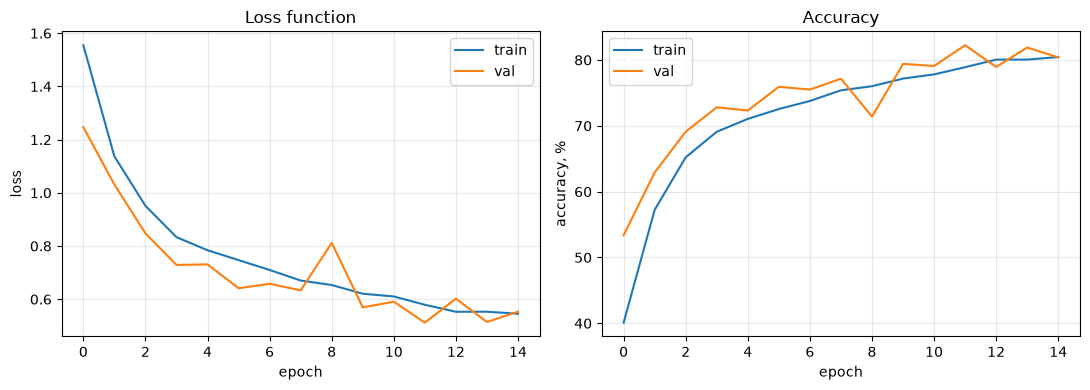

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="val")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss")
axes[0].set_title("Loss function"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(history["train_acc"], label="train")
axes[1].plot(history["val_acc"], label="val")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy, %")
axes[1].set_title("Accuracy"); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [20]:
test_loss, test_acc = run_epoch(model, test_loader, criterion, optimizer=None)
print(f"Test loss: {test_loss:.4f}, Test accuracy: {test_acc:.2f}%")

Test loss: 0.5841, Test accuracy: 79.73%


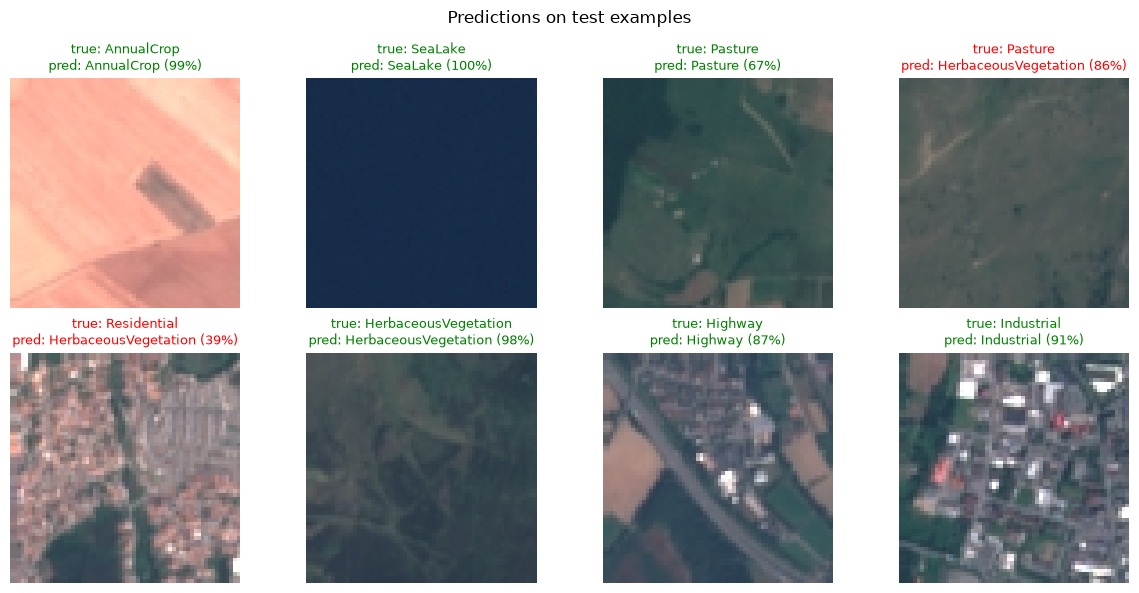

In [ ]:
model.eval()
images, labels = next(iter(test_loader))

with torch.no_grad():
    outputs = model(images.to(device))
    probs = torch.softmax(outputs, dim=1)
    confidences, preds = probs.max(dim=1)
confidences, preds = confidences.cpu(), preds.cpu()

n_show = 8
fig, axes = plt.subplots(2, 4, figsize=(12, 6))


for ax, i in zip(axes.flat, range(n_show)):
    img = (images[i]).clamp(0, 1).permute(1, 2, 0).numpy()
    ax.imshow(img)
    color = "green" if preds[i].item() == labels[i].item() else "red"
    ax.set_title(f"true: {classes[labels[i]]}\npred: {classes[preds[i]]} "
                 f"({confidences[i]*100:.0f}%)", fontsize=9, color=color)
    ax.axis("off")

plt.suptitle("Predictions on test examples")
plt.tight_layout()
plt.show()

### Задача 1.2. Влияние аугментаций на переобучение

Возьмите **маленькое** подмножество train (например, 500-1000 изображений — специально мало,
чтобы спровоцировать переобучение) и обучите одну и ту же архитектуру дважды: без аугментаций и
с аугментациями (`RandomHorizontalFlip`, `RandomRotation`, может быть, `ColorJitter` — обратите
внимание, что для спутниковых снимков избыточный `ColorJitter` может быть неуместен, в отличие
от обычных фото: подумайте, почему).

1. Постройте кривые train/val accuracy по эпохам для обоих случаев на одном графике.
2. Сравните разрыв (gap) между train и val accuracy — с аугментациями он должен быть меньше.
3. Сравните финальную val accuracy — аугментации должны помочь именно на **маленьком** train-сете
   (на большом эффект обычно менее выражен).

In [36]:
# TODO: сравнение с/без аугментаций на маленьком train-сете
full_dataset = torchvision.datasets.EuroSAT(root='.', transform=None, download=True)
classes = full_dataset.classes
print(classes)

n = len(full_dataset)
n_train = int(0.7 * n); n_val = int(0.15 * n); n_test = n - n_train - n_val
train_ds, val_ds, test_ds = random_split(full_dataset, [n_train, n_val, n_test],
                                          generator=torch.Generator().manual_seed(0))
print(f"train={len(train_ds)} val={len(val_ds)} test={len(test_ds)}")

['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
train=18900 val=4050 test=4050


In [37]:
from torch.utils.data import Subset
import random

random.seed(42)

random_indices = random.sample(range(len(train_ds)), 750)

small_train_ds = Subset(train_ds, random_indices)

print(f"Размер уменьшенного датасета: {len(small_train_ds)}")

Размер уменьшенного датасета: 750


In [ ]:
stats_transform = transforms.Compose([
    transforms.ToTensor()
])

full_dataset_for_stats = torchvision.datasets.EuroSAT(root='.', transform=stats_transform, download=True)

stats_loader = DataLoader(full_dataset_for_stats, batch_size=256, num_workers=0, shuffle=False)
channel_sum = torch.zeros(3, dtype=torch.float64)
channel_sq_sum = torch.zeros(3, dtype=torch.float64)
n_pixels = 0

print("Вычисляем mean и std для EuroSAT...")
for images, _ in tqdm(stats_loader, desc="Calculating stats"):
    images = images.double()
    
    channel_sum += images.sum(dim=(0, 2, 3))
    channel_sq_sum += (images ** 2).sum(dim=(0, 2, 3))
    n_pixels += images.numel() // 3

# 5. Финальный расчет
MEAN = (channel_sum / n_pixels).tolist()

STD = ((channel_sq_sum / n_pixels) - (channel_sum / n_pixels) ** 2).sqrt().tolist()

print(f"Найденные значения для EuroSAT:")
print(f"MEAN = {[round(v, 4) for v in MEAN]}")
print(f"STD  = {[round(v, 4) for v in STD]}")

Вычисляем mean и std для EuroSAT...


Calculating stats: 100%|██████████| 106/106 [00:13<00:00,  8.09it/s]

Найденные значения для EuroSAT:
MEAN = [0.3444, 0.3803, 0.4078]
STD  = [0.2027, 0.1369, 0.1156]


In [39]:
train_transform_aug = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomChoice([
        transforms.RandomRotation((0, 0)),    # 0 градусов
        transforms.RandomRotation((90, 90)),  # 90 градусов
        transforms.RandomRotation((180, 180)),# 180 градусов
        transforms.RandomRotation((270, 270)) # 270 градусов
    ]),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])
train_transform_none = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

class TransformedSubset:
    def __init__(self, subset, transform):
        self.subset = subset      # Это объект Subset из random_split
        self.transform = transform

    def __getitem__(self, idx):
        # subset[idx] вернет (PIL_Image, label), так как у full_dataset transform=None
        img, label = self.subset[idx]
        
        # Применяем трансформацию, если она задана
        if self.transform is not None:
            img = self.transform(img)
            
        return img, label

    def __len__(self):
        return len(self.subset)


train_aug_ds = TransformedSubset(small_train_ds, train_transform_aug)
train_aug_none_ds = TransformedSubset(small_train_ds, train_transform_none)
val_ds = TransformedSubset(val_ds, eval_transform)
test_ds = TransformedSubset(test_ds, eval_transform)

print(f"Размеры: train_aug={len(train_aug_ds)}, train_aug_none={len(train_aug_none_ds)},  val={len(val_ds)}, test={len(test_ds)}")

Размеры: train_aug=750, train_aug_none=750,  val=4050, test=4050


In [40]:
BATCH_SIZE = 32
NUM_WORKERS = 0
loader_kwargs = dict(num_workers=NUM_WORKERS, pin_memory=device.type == "cuda",
                     persistent_workers=NUM_WORKERS > 0)
train_aug_loader = DataLoader(train_aug_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
                          **loader_kwargs)
train_aug_none_loader = DataLoader(train_aug_none_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
                          **loader_kwargs)
val_loader = DataLoader(val_ds, batch_size=256, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_ds, batch_size=256, shuffle=False, **loader_kwargs)

images, labels = next(iter(train_aug_loader))
print("Batch shape:", images.shape)

Batch shape: torch.Size([32, 3, 64, 64])


In [41]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),   # 128 -> 64
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),   # 64 -> 32
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),   # 32 -> 16
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),   # global average pooling -> [B, 128, 1, 1]
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes),     # raw logits, no softmax here
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model_aug = SimpleCNN(num_classes=10).to(device)
n_params = sum(p.numel() for p in model_aug.parameters())
print(f"Number of trainable parameters: {n_params:,}")

Number of trainable parameters: 102,154


In [42]:
criterion = nn.CrossEntropyLoss()     # takes raw logits, applies softmax internally
optimizer_aug = optim.Adam(model_aug.parameters(), lr=1e-3)
NUM_EPOCHS = 120

def progress(loader, desc):
    return tqdm(iter(loader), total=len(loader), desc=desc, leave=False)

def run_epoch(model, loader, criterion, optimizer=None):
    """One pass over loader. With an optimizer -- training mode, without -- evaluation."""
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss, correct, total = 0.0, 0, 0
    context = torch.enable_grad() if is_train else torch.no_grad()
    desc = 'train' if is_train else 'eval'
    with context:
        for images, labels in progress(loader, desc):
            images, labels = images.to(device), labels.to(device)

            if is_train:
                optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            if is_train:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += images.size(0)

    return total_loss / total, 100.0 * correct / total

In [43]:
history_aug = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = run_epoch(model_aug, train_aug_loader, criterion, optimizer_aug)
    val_loss, val_acc = run_epoch(model_aug, val_loader, criterion, optimizer=None)

    history_aug["train_loss"].append(train_loss)
    history_aug["train_acc"].append(train_acc)
    history_aug["val_loss"].append(val_loss)
    history_aug["val_acc"].append(val_acc)

    print(f"Epoch {epoch+1}/{NUM_EPOCHS}: "
          f"train_loss={train_loss:.4f} train_acc={train_acc:.2f}% | "
          f"val_loss={val_loss:.4f} val_acc={val_acc:.2f}%")

print("Training complete.")

Epoch 1/120: train_loss=2.1143 train_acc=20.11% | val_loss=1.9295 val_acc=26.27%


Epoch 2/120: train_loss=1.8472 train_acc=34.24% | val_loss=1.7924 val_acc=32.74%


Epoch 3/120: train_loss=1.6425 train_acc=39.40% | val_loss=1.5677 val_acc=38.25%


Epoch 4/120: train_loss=1.5130 train_acc=43.75% | val_loss=1.4684 val_acc=47.38%


Epoch 5/120: train_loss=1.4251 train_acc=46.47% | val_loss=1.3744 val_acc=44.91%


...

Epoch 116/120: train_loss=0.2691 train_acc=89.13% | val_loss=0.7472 val_acc=78.27%


Epoch 117/120: train_loss=0.3391 train_acc=88.04% | val_loss=0.7351 val_acc=78.64%


Epoch 118/120: train_loss=0.3193 train_acc=87.23% | val_loss=0.6795 val_acc=80.25%


Epoch 119/120: train_loss=0.2518 train_acc=91.03% | val_loss=0.7054 val_acc=80.72%


Epoch 120/120: train_loss=0.3062 train_acc=88.04% | val_loss=0.7333 val_acc=78.20%
Training complete.


In [44]:
test_loss, test_acc = run_epoch(model_aug, test_loader, criterion, optimizer=None)
print(f"Test loss: {test_loss:.4f}, Test accuracy: {test_acc:.2f}%")

Test loss: 0.7816, Test accuracy: 78.40%


In [45]:
model_aug_none = SimpleCNN(num_classes=10).to(device)
n_params = sum(p.numel() for p in model_aug_none.parameters())
print(f"Number of trainable parameters: {n_params:,}")

Number of trainable parameters: 102,154


In [46]:
criterion = nn.CrossEntropyLoss()     # takes raw logits, applies softmax internally
optimizer_aug_none = optim.Adam(model_aug_none.parameters(), lr=1e-3)

In [47]:
history_aug_none = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = run_epoch(model_aug_none, train_aug_none_loader, criterion, optimizer_aug_none)
    val_loss, val_acc = run_epoch(model_aug_none, val_loader, criterion, optimizer=None)

    history_aug_none["train_loss"].append(train_loss)
    history_aug_none["train_acc"].append(train_acc)
    history_aug_none["val_loss"].append(val_loss)
    history_aug_none["val_acc"].append(val_acc)

    print(f"Epoch {epoch+1}/{NUM_EPOCHS}: "
          f"train_loss={train_loss:.4f} train_acc={train_acc:.2f}% | "
          f"val_loss={val_loss:.4f} val_acc={val_acc:.2f}%")

print("Training complete.")

Epoch 1/120: train_loss=2.1039 train_acc=19.84% | val_loss=1.8893 val_acc=24.54%


Epoch 2/120: train_loss=1.8423 train_acc=30.16% | val_loss=1.7147 val_acc=38.81%


Epoch 3/120: train_loss=1.6537 train_acc=39.27% | val_loss=1.5810 val_acc=40.84%


Epoch 4/120: train_loss=1.5242 train_acc=41.44% | val_loss=1.4272 val_acc=45.78%


Epoch 5/120: train_loss=1.4772 train_acc=40.76% | val_loss=1.4515 val_acc=43.60%


...

Epoch 116/120: train_loss=0.2087 train_acc=92.80% | val_loss=0.6758 val_acc=80.32%


Epoch 117/120: train_loss=0.2185 train_acc=91.44% | val_loss=0.7199 val_acc=78.52%


Epoch 118/120: train_loss=0.2239 train_acc=91.58% | val_loss=0.7356 val_acc=78.07%


Epoch 119/120: train_loss=0.2455 train_acc=90.76% | val_loss=0.6981 val_acc=79.06%


Epoch 120/120: train_loss=0.1979 train_acc=92.80% | val_loss=0.7122 val_acc=79.78%
Training complete.


In [48]:
test_loss, test_acc = run_epoch(model_aug_none, test_loader, criterion, optimizer=None)
print(f"Test loss: {test_loss:.4f}, Test accuracy: {test_acc:.2f}%")

Test loss: 0.7738, Test accuracy: 78.27%


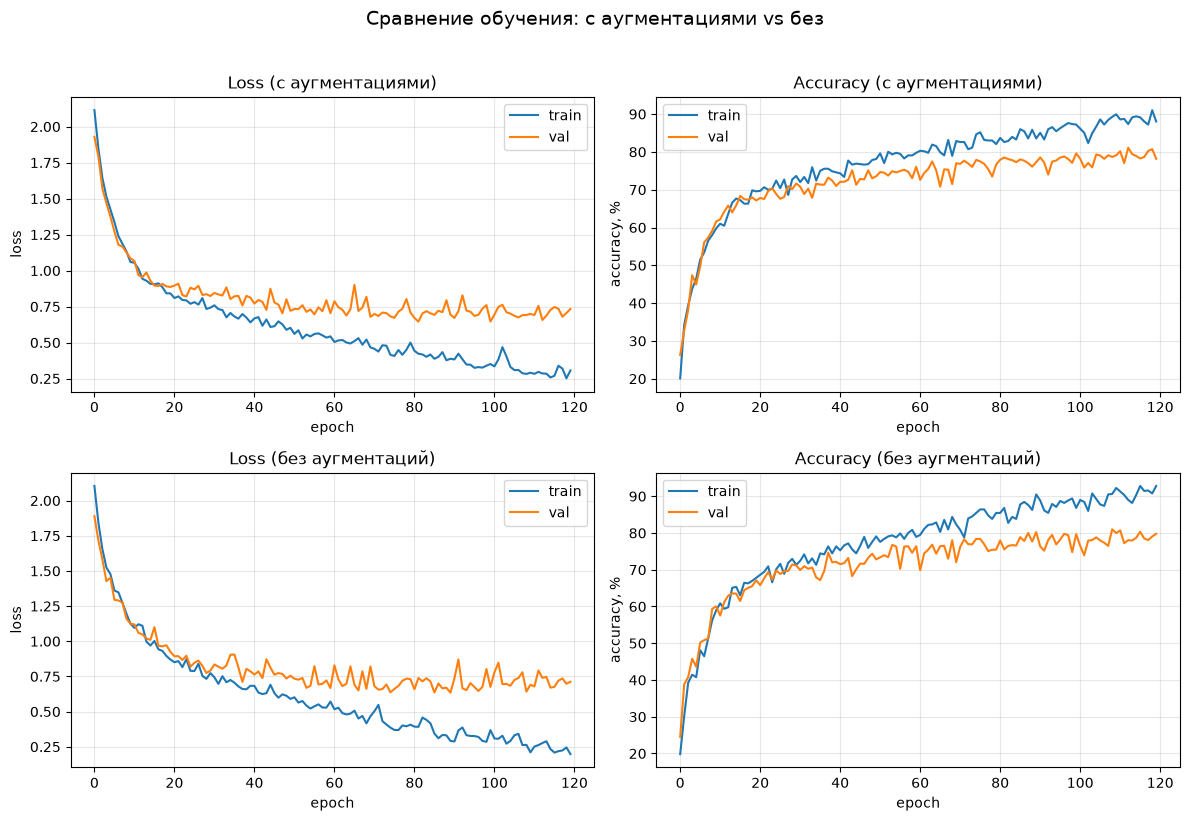

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Верхний левый: Loss с аугментациями
axes[0, 0].plot(history_aug["train_loss"], label="train")
axes[0, 0].plot(history_aug["val_loss"], label="val")
axes[0, 0].set_xlabel("epoch")
axes[0, 0].set_ylabel("loss")
axes[0, 0].set_title("Loss (с аугментациями)")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Верхний правый: Accuracy с аугментациями
axes[0, 1].plot(history_aug["train_acc"], label="train")
axes[0, 1].plot(history_aug["val_acc"], label="val")
axes[0, 1].set_xlabel("epoch")
axes[0, 1].set_ylabel("accuracy, %")
axes[0, 1].set_title("Accuracy (с аугментациями)")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# Нижний левый: Loss без аугментаций
axes[1, 0].plot(history_aug_none["train_loss"], label="train")
axes[1, 0].plot(history_aug_none["val_loss"], label="val")
axes[1, 0].set_xlabel("epoch")
axes[1, 0].set_ylabel("loss")
axes[1, 0].set_title("Loss (без аугментаций)")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# Нижний правый: Accuracy без аугментаций
axes[1, 1].plot(history_aug_none["train_acc"], label="train")
axes[1, 1].plot(history_aug_none["val_acc"], label="val")
axes[1, 1].set_xlabel("epoch")
axes[1, 1].set_ylabel("accuracy, %")
axes[1, 1].set_title("Accuracy (без аугментаций)")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

# Общий заголовок для всего рисунка
plt.suptitle("Сравнение обучения: с аугментациями vs без", fontsize=14, y=1.02)

plt.tight_layout()
plt.show()

### Задача 1.3. Визуализация фильтров и feature maps

В конце `Imagenette.ipynb` показана визуализация весов первого слоя как маленьких изображений.
Разверните эту идею дальше.

1. Визуализируйте все фильтры первого свёрточного слоя (обычно 16-32 штуки) как сетку маленьких
   изображений (`plt.subplots`).
2. Возьмите одно конкретное изображение из test и визуализируйте **feature maps** (выходы) после
   каждого свёрточного блока — как меняется то, что "видит" сеть, по мере углубления?
3. Сравните feature maps **необученной** (случайно инициализированной) сети и **обученной** —
   есть ли качественная разница в том, что выделяют фильтры?

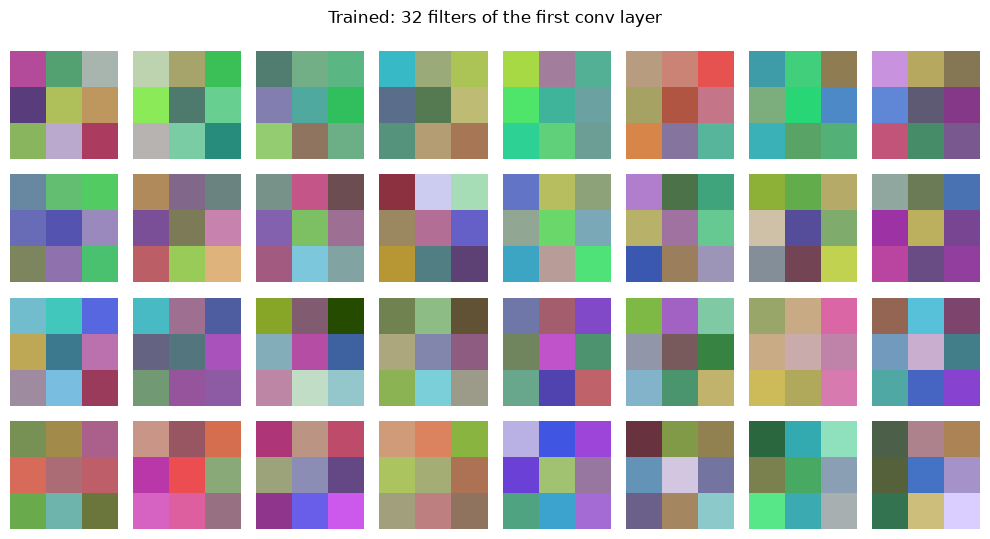

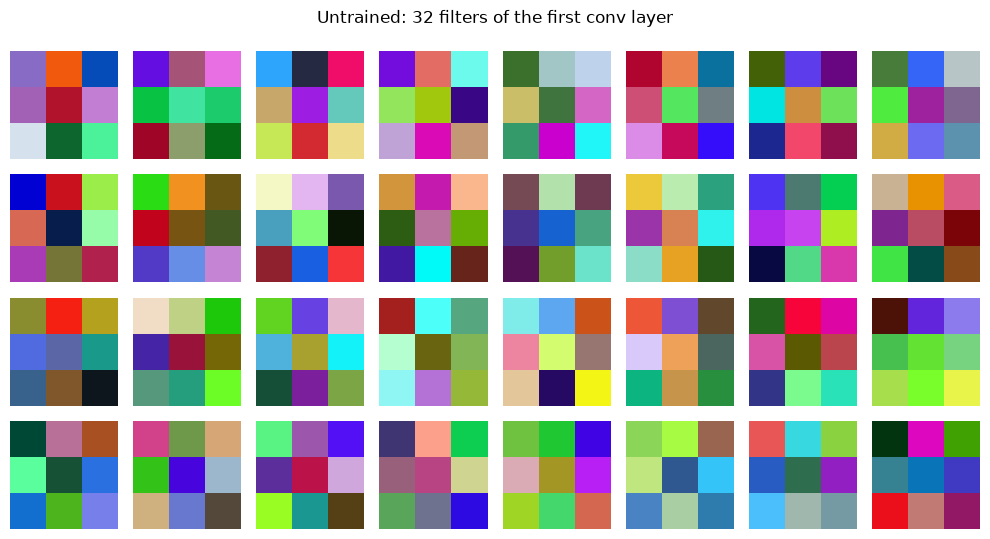

In [50]:
# TODO: визуализация фильтров и feature maps, обученная vs необученная сеть
# Обученная модель
filters = model_aug.features[0].weight.detach().cpu()
f_min, f_max = filters.min(), filters.max()
filters_normed = (filters - f_min) / (f_max - f_min)

fig, axes = plt.subplots(4, 8, figsize=(10, 5.5))
for ax, i in zip(axes.flat, range(filters.shape[0])):
    ax.imshow(filters_normed[i].permute(1, 2, 0).numpy())
    ax.axis("off")
plt.suptitle("Trained: 32 filters of the first conv layer")
plt.tight_layout()
plt.show()

# Необученная модель
model_random = SimpleCNN(num_classes=10).to(device)
filters_rand = model_random.features[0].weight.detach().cpu()
f_min, f_max = filters_rand.min(), filters_rand.max()
filters_rand_normed = (filters_rand - f_min) / (f_max - f_min)

fig, axes = plt.subplots(4, 8, figsize=(10, 5.5))
for ax, i in zip(axes.flat, range(filters_rand.shape[0])):
    ax.imshow(filters_rand_normed[i].permute(1, 2, 0).numpy())
    ax.axis("off")
plt.suptitle("Untrained: 32 filters of the first conv layer")
plt.tight_layout()
plt.show()

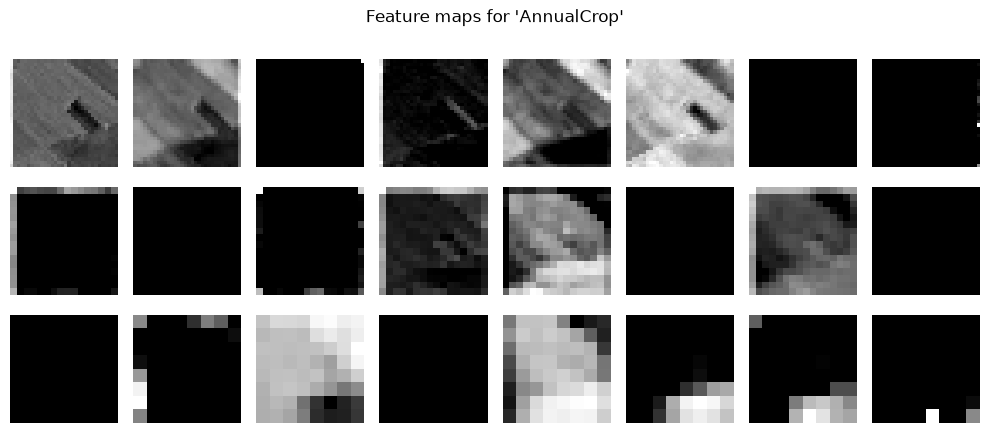

In [56]:
# Берем одно изображение из test
images, labels = next(iter(test_loader))
img = images[0].to(device)
label = labels[0]

# Перехватываем выходы после каждого MaxPool2d (индексы 2, 5, 8)
def make_hook(target_dict, name):
    def hook(module, input, output):
        target_dict[name] = output.detach().cpu()
    return hook

fmaps = {}
hooks = [
    model_aug.features[2].register_forward_hook(make_hook(fmaps, "block1")),
    model_aug.features[5].register_forward_hook(make_hook(fmaps, "block2")),
    model_aug.features[8].register_forward_hook(make_hook(fmaps, "block3")),
]

with torch.no_grad():
    model_aug(img.unsqueeze(0))

for h in hooks:
    h.remove()

# Визуализируем по 8 каналов из каждого блока
fig, axes = plt.subplots(3, 8, figsize=(10, 4.5))
for row, (name, fmap) in enumerate(fmaps.items()):
    fmap = fmap[0]  # убираем batch dim
    for col in range(8):
        ch = fmap[col]
        ch_norm = (ch - ch.min()) / (ch.max() - ch.min() + 1e-8)
        axes[row, col].imshow(ch_norm.numpy(), cmap='gray')
        axes[row, col].axis("off")
    axes[row, 0].set_ylabel(name, fontsize=9, rotation=0, ha='right', va='center')

plt.suptitle(f"Feature maps for '{classes[label]}'")
plt.tight_layout()
plt.show()

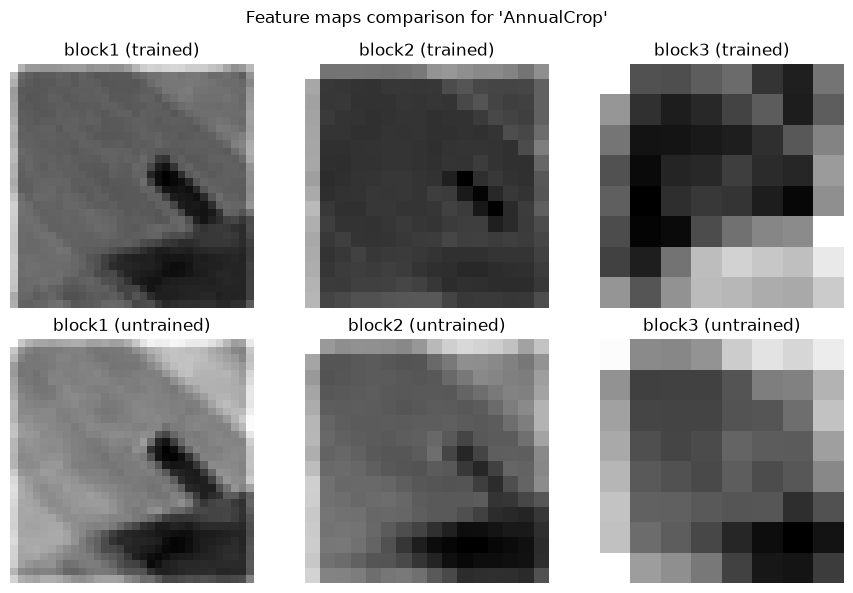

In [57]:
# Feature maps необученной модели
fmaps_rand = {}
hooks_rand = [
    model_random.features[2].register_forward_hook(make_hook(fmaps_rand, "block1")),
    model_random.features[5].register_forward_hook(make_hook(fmaps_rand, "block2")),
    model_random.features[8].register_forward_hook(make_hook(fmaps_rand, "block3")),
]

with torch.no_grad():
    model_random(img.unsqueeze(0))

for h in hooks_rand:
    h.remove()

# Среднее по каналам для наглядности
fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for col, name in enumerate(["block1", "block2", "block3"]):
    avg_trained = fmaps[name][0].mean(dim=0)
    avg_rand = fmaps_rand[name][0].mean(dim=0)
    
    for row, (fmap, title) in enumerate([(avg_trained, "trained"), (avg_rand, "untrained")]):
        normed = (fmap - fmap.min()) / (fmap.max() - fmap.min() + 1e-8)
        axes[row, col].imshow(normed.numpy(), cmap='gray')
        axes[row, col].set_title(f"{name} ({title})")
        axes[row, col].axis("off")

plt.suptitle(f"Feature maps comparison for '{classes[label]}'")
plt.tight_layout()
plt.show()

## Уровень 2. Средний

### Задача 2.1. Глубина и ширина архитектуры: систематическое сравнение

Постройте параметризованную версию `SimpleCNN`, где число блоков (`n_blocks`) и число каналов на
блок (`base_channels`, растущее, например, вдвое с каждым блоком) — параметры конструктора.

1. Обучите несколько конфигураций (например: неглубокая/узкая, неглубокая/широкая,
   глубокая/узкая, глубокая/широкая) на одинаковом числе эпох и одинаковом train-сете.
2. Постройте график: test accuracy vs число параметров модели, а также test accuracy vs время
   обучения одной эпохи.
3. Сделайте вывод: для этой конкретной задачи "больше" (параметров/глубины) всегда means
   "лучше"? Где начинается насыщение или даже деградация?

In [14]:
# TODO: ConfigurableCNN, сравнение нескольких конфигураций глубины/ширины

### Задача 2.2. Batch Normalization: устойчивость к learning rate

Добавьте `nn.BatchNorm2d` после каждого `Conv2d` (до `ReLU`) в `SimpleCNN`. Сравните обучение с
BatchNorm и без при **нескольких** значениях learning rate, включая заведомо агрессивные
(например, `lr=0.01`, `lr=0.05`) — гипотеза: BatchNorm должен позволять использовать более
высокий `lr` без потери стабильности обучения.

1. Обучите 4 комбинации (`use_bn ∈ {False, True}` × `lr ∈ {0.001, 0.02}`) на одинаковом числе
   эпох.
2. Постройте кривые loss по итерациям (не по эпохам — для нестабильного обучения важно видеть
   поведение внутри эпохи) для всех 4 комбинаций на одном графике.
3. Сравните финальные test accuracy.

In [15]:
# TODO: CNN_BN, сравнение с/без BatchNorm при разных lr

### Задача 2.3. Расписания learning rate

Сравните на одинаковом бюджете эпох (например, 15) три варианта изменения learning rate:
константный, `StepLR` (ступенчатое снижение) и `CosineAnnealingLR` (плавное косинусное
снижение до почти нуля).

1. Обучите модель с каждым из трёх расписаний, отслеживая val accuracy по эпохам **и** сам `lr`
   по эпохам (через `scheduler.get_last_lr()`).
2. Постройте два графика рядом: "val accuracy от эпохи" и "lr от эпохи" для всех трёх вариантов.
3. Сравните финальную test accuracy — помогает ли снижение `lr` к концу обучения дожать качество
   по сравнению с константным `lr`?

In [16]:
# TODO: сравнение constant/step/cosine расписаний lr

---
**Что сдавать:** ноутбук с обученными моделями, графиками и письменными ответами на вопросы для
решённых задач. Полный прогон всех задач на EuroSAT — от 30 минут до ~1.5 часов на CPU в
зависимости от числа эпох/подмножества данных, на GPU Colab — заметно быстрее. Если не укладываетесь
в бюджет времени — уменьшите число эпох, размер train-подвыборки или число сравниваемых
конфигураций в задачах 2.1/2.2/2.3, сохранив саму логику сравнения.